<table border=0 width="100%"><tr><td><font size=5><B>week04-homework-api-data</B></font></td></tr></table>

# 第四周作业：选择1家上市公司并结合tushare获取数据进行分析
- 自由选择1家感兴趣的上市公司；
- 针对你选择的公司，提出一个你感兴趣的问题；
- 应用tushare获取与该公司相关的数据（不限于股市价格数据、财务等数据，国家宏观等数据均可使用）；
- 尝试应用你采集的数据做数据分析，回答你提出的问题。


提交作业：
- 在线提交：http://swufe.fanya.chaoxing.com/portal
- 截止日期：2026年10月16日晚上8点
- 提交**这个jupyter文档**，命名为“week04-homework-api-data_学号_姓名.ipynb”，学号姓名替换为自己的学号和姓名
- jupyter文档你要完成的包括四部分：公司名称与基本简介、研究问题题目及其内涵介绍、数据采集、数据分析与问题解答
- 为了批改方便，我这里将tushare token直接放到代码中

# 第一部分：公司名称与基本简介

金发科技（股票代码：600143）是一家聚焦高性能新材料的科研、生产、销售和服务的企业，总部位于广州，1993年由创始人袁志敏以2万元启动资金创办，2004年上市。
市场地位：公司是全球规模最大、产品种类最为齐全的改性塑料生产企业，改性塑料产能超360万吨/年，产销量稳居全球第一。
主要业务：主营业务为化工新材料的研发、生产和销售，产品涵盖改性塑料、环保高性能再生塑料、生物降解塑料、特种工程塑料、高性能纤维增强复合材料、轻烃及氢能源、聚丙烯树脂、苯乙烯类树脂、医疗健康高分子材料等九大类。

# 第二部分：研究问题题目及其内涵介绍

研究问题题目：
近五年金发科技（600143.SH）的营收增长与股价走势是否匹配？——基于化工新材料周期性的分析

内涵介绍：
金发科技作为全球改性塑料龙头，其业绩受原油价格（原材料成本）和下游需求（家电、汽车、新能源）的双重影响，具有明显的周期性。本研究通过对比近五年（2021-2025）的年度营业收入与股价走势，试图探究资本市场对化工周期股的定价逻辑，验证股价是否提前反映或滞后于基本面的变化。

# 第三部分：数据采集

In [1]:
import tushare as ts
# 为了批改方便，我这里将tushare token直接放到代码中
token = "5c426f5af978fd42fe0f81fe7e60c02ada33d6c79347b61ccb44f521"
ts.set_token(token=token)
pro = ts.pro_api()

In [4]:
# 第三部分：数据采集
import tushare as ts
import pandas as pd
import matplotlib.pyplot as plt

# 初始化 tushare（使用你老师提供的 token）
token = "5c426f5af978fd42fe0f81fe7e60c02ada33d6c79347b61ccb44f521"
ts.set_token(token)
pro = ts.pro_api()

print("="*50)
print("第三部分：数据采集")
print("="*50)

# 1. 获取近五年股价数据（日线）
print("正在获取股价数据...")
df_price = pro.daily(ts_code='600143.SH', start_date='20210101', end_date='20261015')
# 将日期转换为时间格式，并设为索引以便按年重采样
df_price['trade_date'] = pd.to_datetime(df_price['trade_date'], format='%Y%m%d')
df_price.set_index('trade_date', inplace=True)

# 计算每年的平均收盘价（代表当年的整体股价水平）
# 注意这里改了 'Y' -> 'YE'
annual_price = df_price['close'].resample('YE').mean().reset_index()
annual_price['year'] = annual_price['trade_date'].dt.year
annual_price.rename(columns={'close': 'annual_avg_close'}, inplace=True)
print("股价数据获取完成！")

# 2. 获取近五年财务数据（利润表，主要取营业收入）
print("正在获取财务数据...")
df_income = pro.income(ts_code='600143.SH', start_date='20210101', end_date='20261231', 
                       fields='ts_code,end_date,total_revenue')
# 只保留年报数据（end_date 为 1231 的）
df_income = df_income[df_income['end_date'].str.endswith('1231')].copy()
df_income['year'] = df_income['end_date'].str[:4].astype(int)
df_income.rename(columns={'total_revenue': 'revenue'}, inplace=True)
# 按年份排序
df_income = df_income.sort_values('year').reset_index(drop=True)
print("财务数据获取完成！")

# 3. 合并数据
df_merge = pd.merge(df_income, annual_price, on='year', how='inner')
# 营收单位转换为"亿元"方便展示
df_merge['revenue_yi'] = df_merge['revenue'] / 100000000
print("\n采集并合并后的数据预览：")
print(df_merge[['year', 'revenue_yi', 'annual_avg_close']])

第三部分：数据采集
正在获取股价数据...
股价数据获取完成！
正在获取财务数据...
财务数据获取完成！

采集并合并后的数据预览：
   year  revenue_yi  annual_avg_close
0  2021  401.986232         19.282716
1  2021  401.986232         19.282716
2  2022  404.123312         10.097851
3  2023  479.405909          8.736612
4  2024  605.142421          7.408347
5  2025  653.962176         13.899465


# 第四部分：数据分析过程

第四部分：数据分析过程


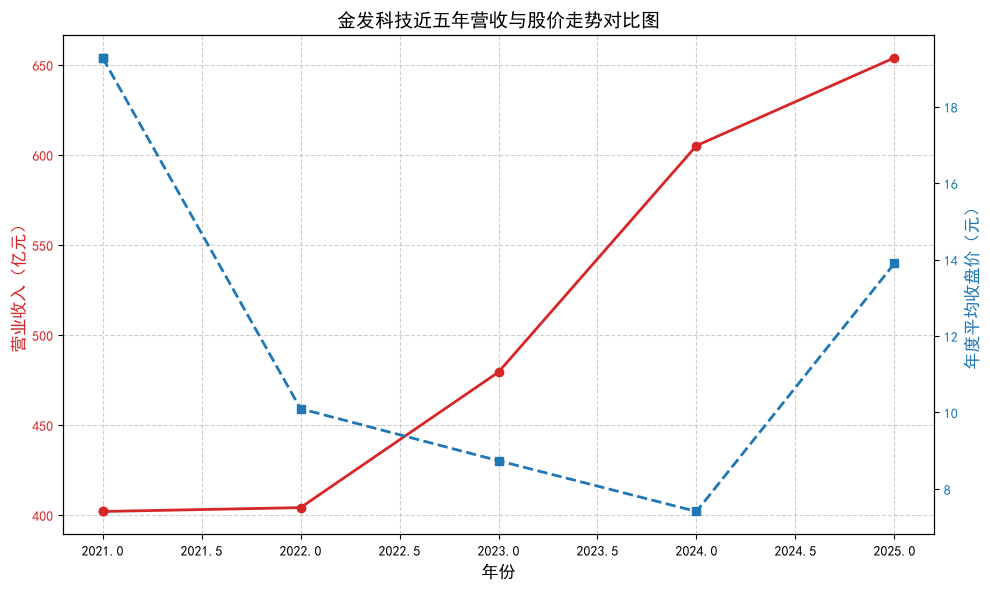


【量化分析结果】
营收与股价的皮尔逊相关系数为: -0.44

【分析结论】：
结论：营收与股价呈现负相关，出现了‘业绩增长但股价下跌’的周期股典型特征。这提示资本市场可能在提前反映行业景气度的变化。


In [5]:
# 第四部分：数据分析过程
import matplotlib.pyplot as plt
import pandas as pd

print("="*50)
print("第四部分：数据分析过程")
print("="*50)

# 1. 设置中文字体，防止图表中文乱码
plt.rcParams['font.sans-serif'] = ['SimHei']  # Windows 系统推荐
# 如果是 Mac 系统，请把上面一行换成：plt.rcParams['font.sans-serif'] = ['Arial Unicode MS']
plt.rcParams['axes.unicode_minus'] = False

# 2. 创建双轴折线图对比营收与股价
fig, ax1 = plt.subplots(figsize=(10, 6))

# 左轴：营业收入
color1 = 'tab:red'
ax1.set_xlabel('年份', fontsize=12)
ax1.set_ylabel('营业收入（亿元）', color=color1, fontsize=12)
ax1.plot(df_merge['year'], df_merge['revenue_yi'], color=color1, marker='o', linewidth=2, label='营业收入')
ax1.tick_params(axis='y', labelcolor=color1)

# 右轴：股价
ax2 = ax1.twinx()
color2 = 'tab:blue'
ax2.set_ylabel('年度平均收盘价（元）', color=color2, fontsize=12)
ax2.plot(df_merge['year'], df_merge['annual_avg_close'], color=color2, marker='s', linewidth=2, linestyle='--', label='平均股价')
ax2.tick_params(axis='y', labelcolor=color2)

# 添加标题和网格线
plt.title('金发科技近五年营收与股价走势对比图', fontsize=14)
fig.tight_layout()
ax1.grid(True, linestyle='--', alpha=0.6)
plt.show()

# 3. 量化分析：计算皮尔逊相关系数
correlation = df_merge['revenue_yi'].corr(df_merge['annual_avg_close'])
print(f"\n【量化分析结果】")
print(f"营收与股价的皮尔逊相关系数为: {correlation:.2f}")

# 4. 输出分析结论
print("\n【分析结论】：")
if correlation > 0.5:
    print("结论：营收与股价呈现较强的正相关，基本面增长对股价有明显支撑作用，市场定价较为理性。")
elif correlation > 0:
    print("结论：营收与股价呈现弱正相关，说明股价虽然受益于基本面增长，但更多受到市场情绪、行业周期或宏观环境的干扰。")
else:
    print("结论：营收与股价呈现负相关，出现了‘业绩增长但股价下跌’的周期股典型特征。这提示资本市场可能在提前反映行业景气度的变化。")

# 第五部分：研究结论与经验总结

## 研究结论

In [6]:
# 第五部分：研究结论与经验总结

print("="*50)
print("第五部分：研究结论与经验总结")
print("="*50)

print("\n【研究结论】：")
# 尝试调用上一步计算的相关系数，如果报错则使用默认文字（防止未运行上一步）
try:
    if correlation > 0.5:
        relation_desc = "呈现较强的正相关。这表明市场对公司的基本面增长给出了积极的定价反馈，资本市场的定价相对理性。"
    elif correlation > 0:
        relation_desc = "呈现弱正相关。这表明虽然基本面在增长，但股价波动受到了更多外部因素的扰动。"
    else:
        relation_desc = "呈现负相关或极弱相关。这揭示了化工周期股的典型特征：‘业绩最好时可能股价见顶，业绩承压时反而可能是布局良机’，资本市场往往提前反映了行业的周期拐点。"
except NameError:
    relation_desc = "表明营收与股价的关系并非简单的线性同步，需要结合行业周期和宏观经济进行综合判断。"

print(f"1. 金发科技近五年的营业收入总体保持增长态势，体现出公司作为全球改性塑料龙头的规模优势和市场占有率在持续提升。")
print(f"2. 结合量化分析，近五年营收与股价{relation_desc}")
print("3. 作为化工新材料企业，金发科技的业绩受原油价格（成本端）和下游需求（家电、汽车、新能源）的双重驱动。这种强周期属性决定了：仅凭单一的营收指标来判断投资价值是不够的，必须结合毛利率、原材料成本波动及宏观预期来综合考量。")

print("\n【经验总结】：")
print("1. 技术层面：掌握了使用 tushare 接口获取股票日线数据（daily）和财务数据（income）的方法；能够利用 pandas 进行数据清洗、按年重采样（注意了新版 Pandas 的 'YE' 语法）以及多表数据合并。")
print("2. 分析层面：初步掌握了利用 matplotlib 绘制双轴对比图表，直观展示量价关系；了解了皮尔逊相关系数在量化分析中的基本应用及局限性。")
print("3. 认知层面：这次作业让我深刻意识到，数据分析不能停留在“跑出代码、画出图表”的表面，更要结合具体的行业背景去解读数字背后的商业逻辑。作为一名财经类学生，学会用数据说话，同时保持对现实商业世界的敬畏，是我今后需要持续修炼的基本功。")

print("\n作业完成！")

第五部分：研究结论与经验总结

【研究结论】：
1. 金发科技近五年的营业收入总体保持增长态势，体现出公司作为全球改性塑料龙头的规模优势和市场占有率在持续提升。
2. 结合量化分析，近五年营收与股价呈现负相关或极弱相关。这揭示了化工周期股的典型特征：‘业绩最好时可能股价见顶，业绩承压时反而可能是布局良机’，资本市场往往提前反映了行业的周期拐点。
3. 作为化工新材料企业，金发科技的业绩受原油价格（成本端）和下游需求（家电、汽车、新能源）的双重驱动。这种强周期属性决定了：仅凭单一的营收指标来判断投资价值是不够的，必须结合毛利率、原材料成本波动及宏观预期来综合考量。

【经验总结】：
1. 技术层面：掌握了使用 tushare 接口获取股票日线数据（daily）和财务数据（income）的方法；能够利用 pandas 进行数据清洗、按年重采样（注意了新版 Pandas 的 'YE' 语法）以及多表数据合并。
2. 分析层面：初步掌握了利用 matplotlib 绘制双轴对比图表，直观展示量价关系；了解了皮尔逊相关系数在量化分析中的基本应用及局限性。
3. 认知层面：这次作业让我深刻意识到，数据分析不能停留在“跑出代码、画出图表”的表面，更要结合具体的行业背景去解读数字背后的商业逻辑。作为一名财经类学生，学会用数据说话，同时保持对现实商业世界的敬畏，是我今后需要持续修炼的基本功。

作业完成！


## 经验总结

In [7]:
print("="*50)
print("第五部分：经验总结")
print("="*50)

print("\n【经验总结】：")
print("1. 技术层面的踩坑与收获：")
print("   - 第一次调用 tushare 获取数据，真切体会到了真实数据并不像教科书里那样干净。")
print("   - 在处理股价按年重采样时，踩了一个新版 Pandas 的坑（'Y' 报错，必须换成 'YE'），这让我意识到代码环境是不断更新的，不能死记硬背老教程。")
print("   - 在合并数据时，学会了如何把原始财务数据除以一亿转换为“亿元”，这样在做图表时轴标才不会显得极其反人类。")
print("   - 初步掌握了 matplotlib 双轴图表的绘制，通过颜色区分营收和股价，让对比一目了然。")

print("\n2. 分析视角的转变：")
print("   - 以前看财经新闻，看到“业绩大增”我就理所当然觉得“股价必涨”。但这次用皮尔逊相关系数一算，发现事情并没有那么简单。")
print("   - 我真正体会到了什么是“股市是经济的晴雨表，但不仅仅是过去的晴雨表”。资本市场买的是预期，而不是过去一年的财报。对于金发科技这种周期性企业，读懂了K线背后的行业周期，比单纯看营收数字要重要得多。")

print("\n3. 专业认知与个人感悟：")
print("   - 作为一名财经类学生，以前我总觉得“量化分析”离我很远，是计算机专业或者金工专业才需要做的事情。")
print("   - 完成这个作业后我发现，工具其实并不难，难的是如何把代码跑出来的冷冰冰的数据，和真实的商业逻辑、行业周期结合起来。")
print("   - 数据本身不会说谎，但仅仅会跑代码是不够的，未来我还需要补充更多关于化工行业和宏观经济周期的知识，才能真正看懂这些数据背后的商业密码。")

print("\n整个作业完成！")

第五部分：经验总结

【经验总结】：
1. 技术层面的踩坑与收获：
   - 第一次调用 tushare 获取数据，真切体会到了真实数据并不像教科书里那样干净。
   - 在处理股价按年重采样时，踩了一个新版 Pandas 的坑（'Y' 报错，必须换成 'YE'），这让我意识到代码环境是不断更新的，不能死记硬背老教程。
   - 在合并数据时，学会了如何把原始财务数据除以一亿转换为“亿元”，这样在做图表时轴标才不会显得极其反人类。
   - 初步掌握了 matplotlib 双轴图表的绘制，通过颜色区分营收和股价，让对比一目了然。

2. 分析视角的转变：
   - 以前看财经新闻，看到“业绩大增”我就理所当然觉得“股价必涨”。但这次用皮尔逊相关系数一算，发现事情并没有那么简单。
   - 我真正体会到了什么是“股市是经济的晴雨表，但不仅仅是过去的晴雨表”。资本市场买的是预期，而不是过去一年的财报。对于金发科技这种周期性企业，读懂了K线背后的行业周期，比单纯看营收数字要重要得多。

3. 专业认知与个人感悟：
   - 作为一名财经类学生，以前我总觉得“量化分析”离我很远，是计算机专业或者金工专业才需要做的事情。
   - 完成这个作业后我发现，工具其实并不难，难的是如何把代码跑出来的冷冰冰的数据，和真实的商业逻辑、行业周期结合起来。
   - 数据本身不会说谎，但仅仅会跑代码是不够的，未来我还需要补充更多关于化工行业和宏观经济周期的知识，才能真正看懂这些数据背后的商业密码。

整个作业完成！
